# AHPSN · demo local con CUDA

Carga el checkpoint `checkpoints/speech_original/unjiabqs/ultimo.pt` del entrenamiento de 2.001 pasos y predice los fonemas de una frase de test. Recupera la arquitectura, el vocabulario y la normalización de train desde los pesos.

Dibuja la actividad neuronal y realiza la predicción en la celda siguiente. La configuración está en `configs/speech_demo.yaml` y los datos proceden de `data/speech_2023/competitionData`.


In [2]:
# 1. Usar el entorno local y comprobar CUDA
from pathlib import Path
import os
import sys

here = Path.cwd().resolve()
ROOT = next((folder for folder in [here, *here.parents]
             if (folder / 'configs/speech_demo.yaml').is_file()), None)
if ROOT is None:
    raise RuntimeError('Abre el notebook desde la carpeta tic_proyecto o notebooks/.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import yaml
cfg = yaml.safe_load(Path('configs/speech_demo.yaml').read_text())
for variable in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ[variable] = str(cfg['ejecucion']['hilos_cpu'])
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'runs/matplotlib'))

import torch
torch.set_num_threads(cfg['ejecucion']['hilos_cpu'])
DEVICE = torch.device(cfg['ejecucion']['dispositivo'])
if DEVICE.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('Este kernel no detecta CUDA. Selecciona .venv/bin/python del proyecto y comprueba el controlador NVIDIA.')
print('Python:', sys.executable)
print('PyTorch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('Dispositivo:', torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else DEVICE)


Python: /run/media/hjasi/neural_data/Trabajo Integrado/tic_proyecto/.venv/bin/python
PyTorch: 2.5.1+cu124 | CUDA: 12.4
Dispositivo: NVIDIA GeForce RTX 2060


In [4]:
# 2. Cargar el checkpoint entrenado
from datetime import datetime
from uuid import uuid4
import json
from scripts.demo_speech import inspect_checkpoint, prepare_example, predict_example

CHECKPOINT = Path(cfg['checkpoint'])
CORPUS = Path(cfg['datos']['raiz'])
if not CHECKPOINT.is_file():
    raise FileNotFoundError(
        f'Falta {CHECKPOINT}. Copia aquí el ultimo.pt de tu entrenamiento unjiabqs '
        'o cambia checkpoint en configs/speech_demo.yaml. No se usarán otros pesos automáticamente.'
    )
RUN = Path(cfg['salida']['directorio']) / (datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid4().hex[:8])
info = inspect_checkpoint(CHECKPOINT, RUN)
print('Resultados de la demo:', RUN)


Checkpoint leído: checkpoints/speech_original/unjiabqs/ultimo.pt
Paso guardado: 2001
Modelo: {'nombre': 'speech_gru', 'entrada': 256, 'capa_dia': 256, 'capas': 5, 'unidades': 1024, 'bidireccional': False, 'kernel': 32, 'stride': 4, 'dropout_entrada': 0.2, 'dropout_gru': 0.4}
Sesiones disponibles: t12.2022.04.28, t12.2022.05.05, t12.2022.05.17, t12.2022.05.19, t12.2022.05.24, t12.2022.05.26, t12.2022.06.02, t12.2022.06.07, t12.2022.06.14, t12.2022.06.16, t12.2022.06.21, t12.2022.06.28, t12.2022.07.05, t12.2022.07.14, t12.2022.07.21, t12.2022.07.27, t12.2022.08.02, t12.2022.08.11, t12.2022.08.13
Resultados de la demo: runs/demo_ahpsn/20261020_161906_d55e1d83


Frase de referencia: Theocracy reconsidered.
Sesión: t12.2022.04.28 · test[0] · bloque 17
Entrada real del modelo: [254, 256] · duración 5.08 s


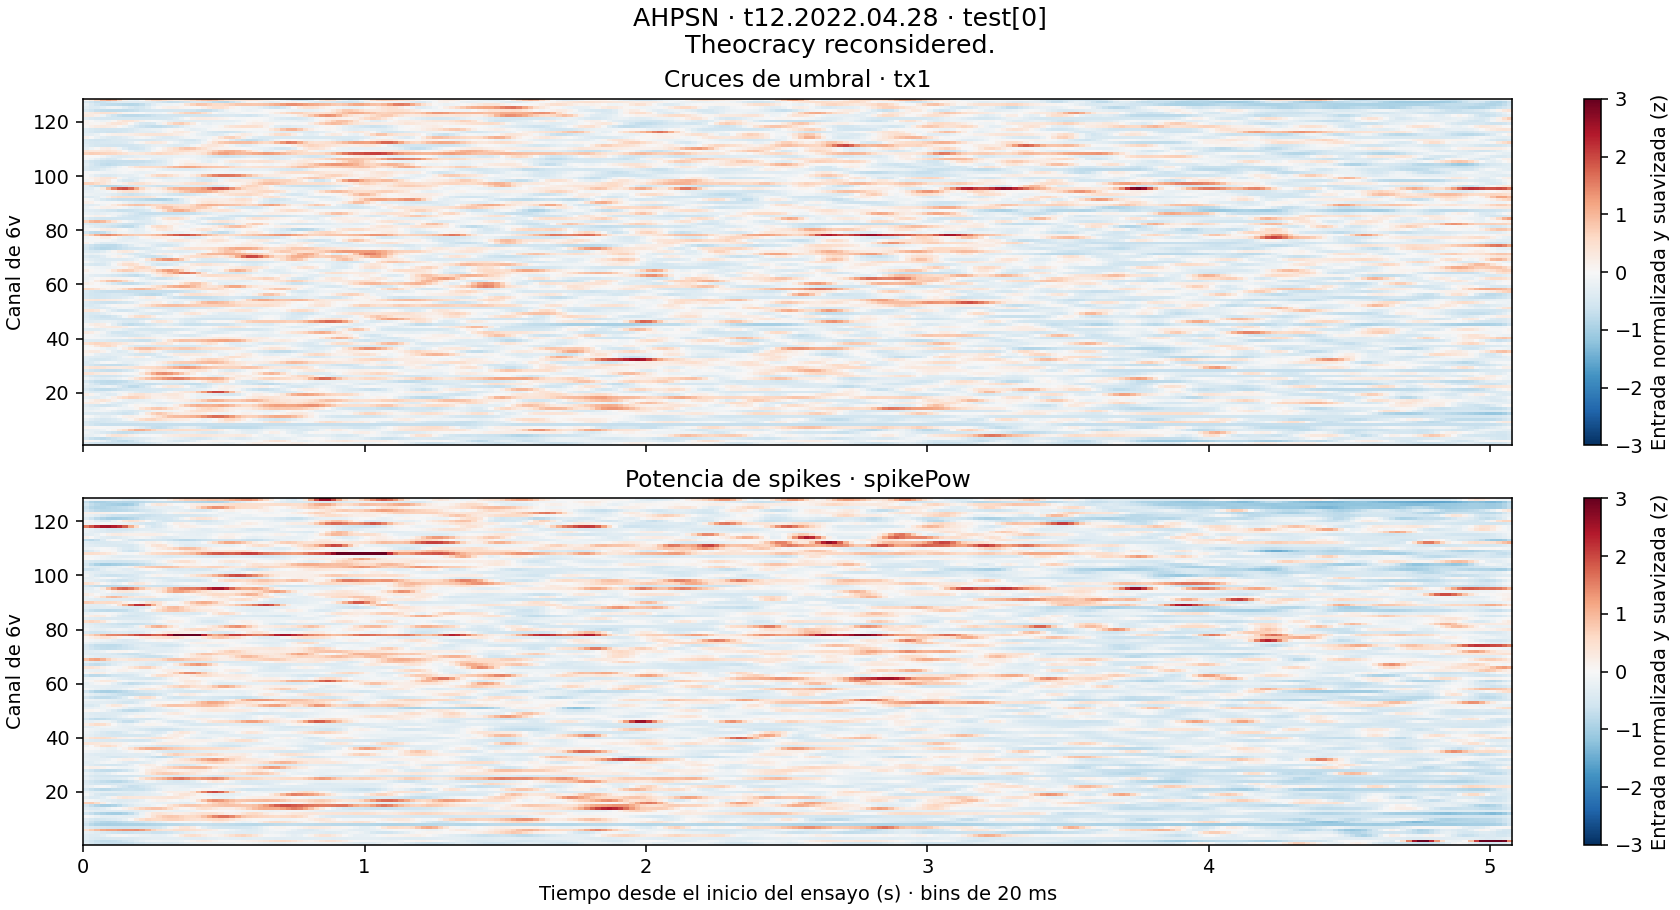

In [5]:
# 3. Elegir una frase del test y dibujar su actividad neuronal
from IPython.display import Image, display

SESION = cfg['datos']['sesion']
FRASE = cfg['datos']['frase']  # Índice desde cero. Cambia este valor para mostrar otra frase.
example = prepare_example(CHECKPOINT, CORPUS, SESION, FRASE, RUN, cfg)
display(Image(filename=str(RUN / 'actividad_neuronal.png')))


In [6]:
# 4. Predecir los fonemas de la actividad de la celda anterior con tu GPU
prepared = json.loads((RUN / 'ejemplo.json').read_text())
if prepared['session'] != SESION or prepared['trial_index'] != FRASE:
    raise RuntimeError('La selección cambió. Vuelve a ejecutar la celda de actividad.')
# El modelo recibe señal e ID de sesión. El texto solo se usa para comparar después.
result = predict_example(CHECKPOINT, RUN, cfg)
print('Frase de referencia:', result['reference_text'])
print('GPU:', result['hardware'])
print('Resultados guardados:', RUN)


FONEMAS PREDICHOS:
DH AH S K AH K IY SIL R IH G EH N IH T ER SIL

FONEMAS DE REFERENCIA (g2p-en):
TH IY AA K R AH S IY SIL R IY K AH N S IH D ER D SIL

PER de esta frase: 55.00% (11/20) · incluye SIL
Inferencia: 0.127 s · cuda · cero actualizaciones
Frase de referencia: Theocracy reconsidered.
GPU: NVIDIA GeForce RTX 2060
Resultados guardados: runs/demo_ahpsn/20261020_161906_d55e1d83


Los mapas muestran los 128 canales de 6v de `tx1` y `spikePow`, normalizados con las estadísticas de train del checkpoint y suavizados. El color se satura en ±3 para facilitar la lectura; la entrada del modelo conserva sus valores.
